# 03 · Differential expression (DESeq2)
**Goal:** genes that differ between groups: aging (older vs 3 months, and their course over age) and each treatment vs its control. **Input:** the gene counts of one method (`METHOD`; **RSEM** is the main one, notebook 04 checks the others). **Output:** `results/de/<METHOD>/*.csv` (not in git). **Kernel:** R (`ir`) · **Time:** ~1 min.

**Method.** DESeq2 fits a negative binomial model per gene and tests whether the log2 fold change differs from 0; padj < 0.05 = differentially expressed gene (DEG). Genes need ≥ 10 counts in at least as many samples as the smallest group to be tested.

**Design.** The aging and rejuvenation mice come from different experiments, so they are analysed **separately**, each treatment against its own control:

| Analysis | Mice | Model | Comparison |
|---|---|---|---|
| Aging | 12 (3 / 18 / 21 months, 2 male + 2 female each) | `~ sex + group` | 18 vs 3, 21 vs 3 months |
| aDR | 9 females (AL 4, aDR 5) | `~ group` | aDR vs AL |
| YMP | 6 males (PBS 3, YMP 3) | `~ group` | YMP vs PBS |

Terms: [docs/glossary.md](../docs/glossary.md).

In [1]:
# samples: one row per run; genes: gene id -> symbol; txi: gene-level counts of METHOD
source('../R/helpers.R')
samples <- load_samples()
genes <- load_genes()
METHOD <- 'RSEM'   # or 'kallisto' / 'STAR' to repeat the analysis with another method
txi <- switch(METHOD, RSEM = load_rsem(rownames(samples)), kallisto = load_txi(rownames(samples))$txi, STAR = load_star_counts()[, rownames(samples)])
dir.create(file.path(ROOT, 'results/de', METHOD), recursive = TRUE, showWarnings = FALSE)
cat(METHOD, ':', if (is.matrix(txi)) nrow(txi) else nrow(txi$counts), 'genes x', nrow(samples), 'samples\n')
dplyr::count(samples, cohort, group, sex)

RSEM : 78289 genes x 27 samples


cohort,group,sex,n
<chr>,<fct>,<fct>,<int>
aging,aging 3mo,female,2
aging,aging 3mo,male,2
aging,aging 18mo,female,2
aging,aging 18mo,male,2
aging,aging 21mo,female,2
aging,aging 21mo,male,2
rejuvenation,AL,female,4
rejuvenation,aDR,female,5
rejuvenation,PBS,male,3


## 1 · All 27 samples: the cohort effect
Two views of sample similarity on the variance-stabilised counts: a PCA, and a hierarchical clustering on pairwise correlations. Both should separate the two cohorts, which is why they are not pooled.

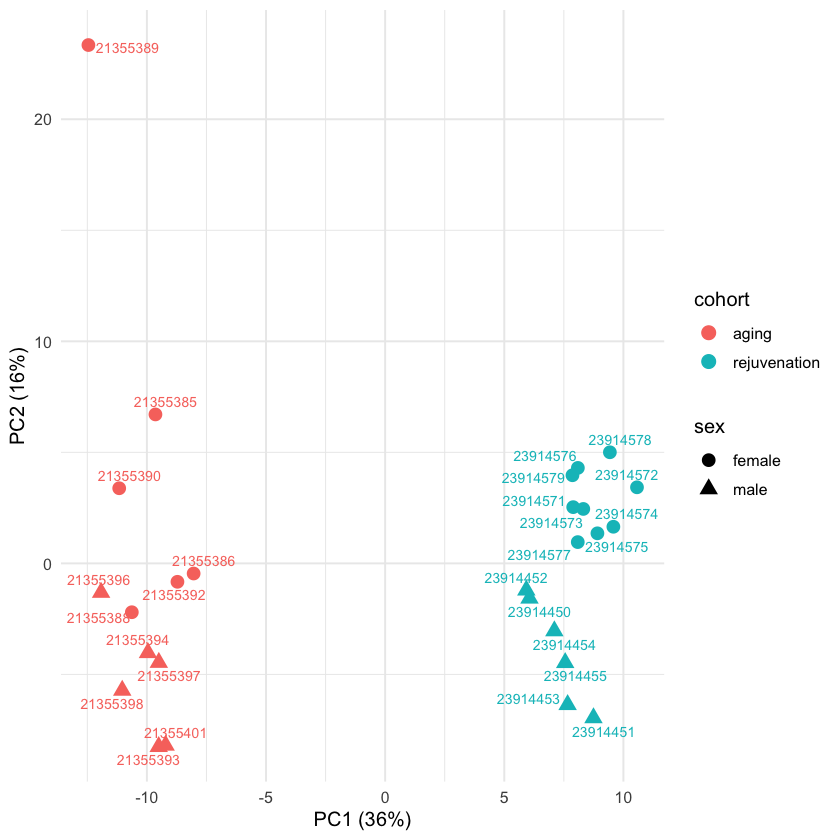

In [2]:
# DESeq2 dataset of all 27 samples; design ~ 1 = no groups (only for the plot, nothing is tested here);
# genes with >= 10 counts in >= 4 samples are kept
dds_all <- make_dds(txi, samples, ~ 1, min_n = 4)
# PCA of the variance-stabilised counts (vst, blind to the groups); colour = cohort, shape = sex, label = run number
pca_plot(dds_all, 'cohort', 'sex')

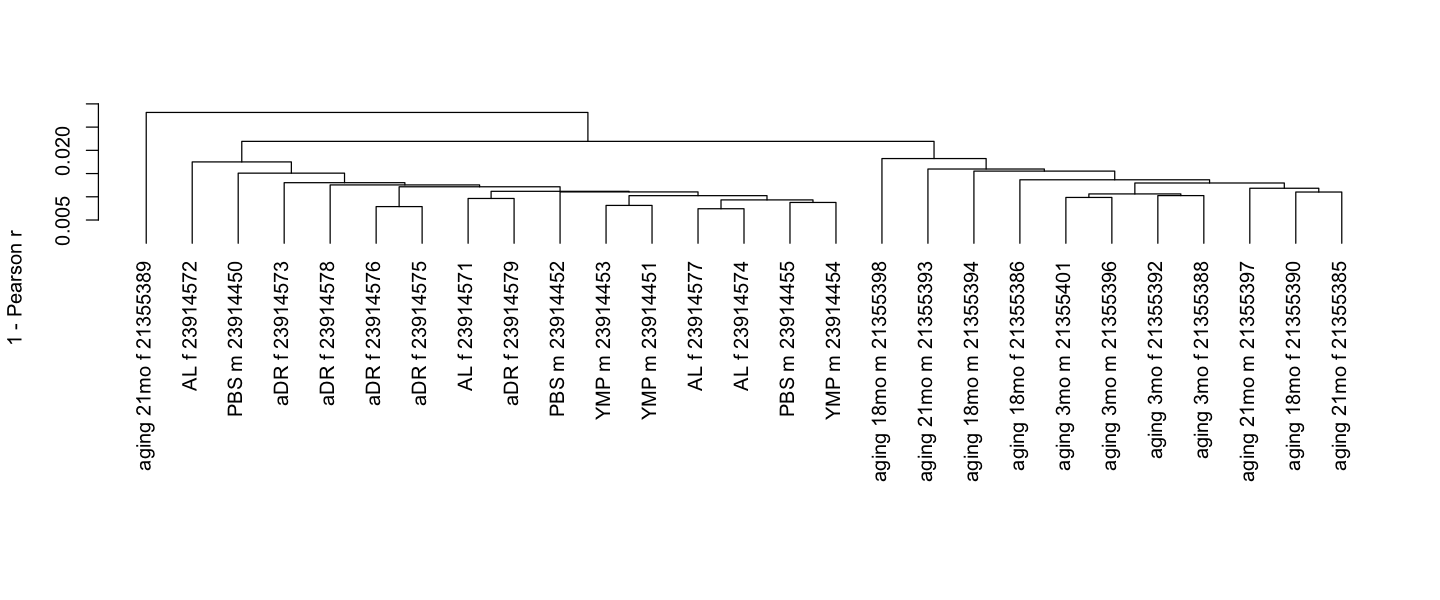

In [3]:
# hierarchical clustering of the samples: distance = 1 - Pearson correlation of the vst values (same genes as the PCA)
options(repr.plot.width = 12, repr.plot.height = 5)
hc_all <- sample_tree(dds_all)

**Reading.** The outlier SRR21355389 branches off first, then the two cohorts split completely. Within the aging cohort the four 3-month mice form one branch, while 18 and 21 months are mixed. Within the rejuvenation cohort the groups do not form their own branches: the treatment effects are small compared with the differences between mice. All samples are very similar (1 − r < 0.03 at every merge), as expected for one tissue.

## 2 · Aging cohort (3, 18, 21 months)
### 2a · Outlier check
With all 12 mice, one 21-month female (SRR21355389) sits far from the others on PC1.

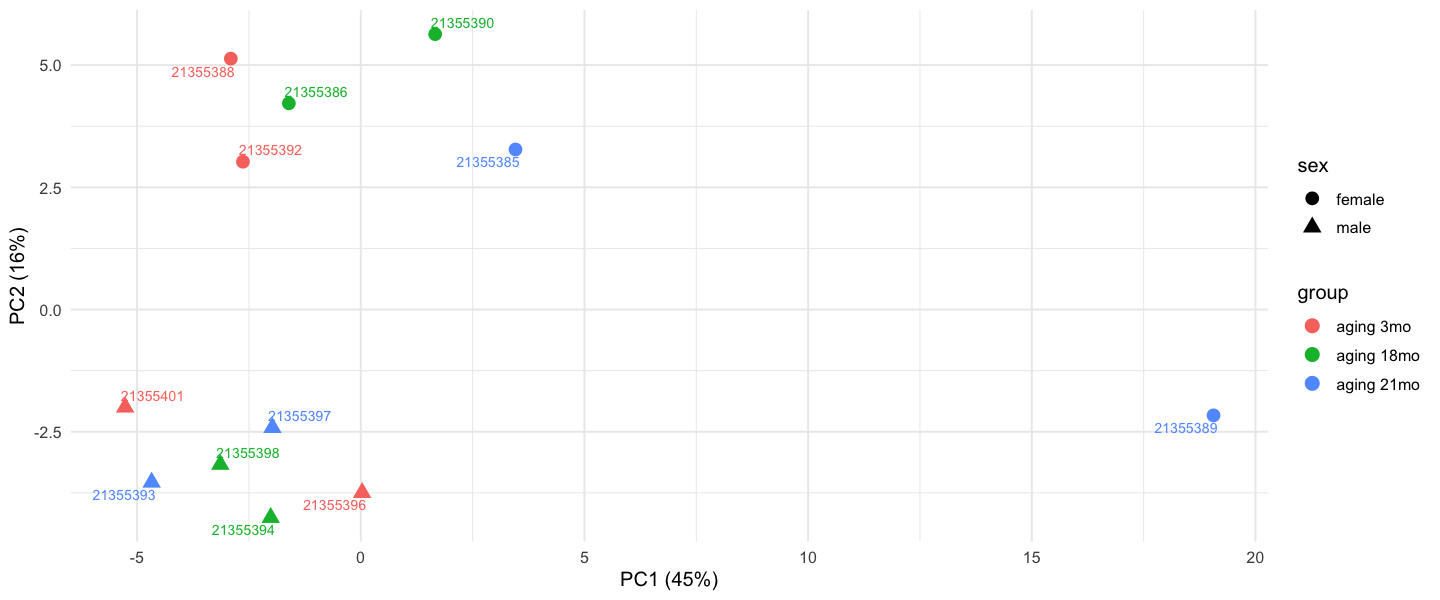

In [4]:
# aging mice only, all 12; PCA coloured by age group
s_age_all <- samples %>% filter(cohort == 'aging') %>% mutate(group = droplevels(group))
dds_age_all <- make_dds(txi, s_age_all, ~ sex + group, min_n = 4)
pca_plot(dds_age_all, 'group', 'sex')

In [5]:
# the 10 genes that most distinguish SRR21355389 from the other 11 aging mice: its vst value minus their mean (≈ log2 difference)
outlier_genes(dds_age_all, 'SRR21355389', genes)

symbol,vst_diff
<chr>,<dbl>
Hbb-bs,5.074086
Hba-a1,5.045218
S100a8,4.830856
Hba-a2,4.697898
Hbb-bt,4.472360
Ngp,4.371122
S100a9,4.327058
Col1a1,3.795261
Col1a2,3.192967


Its top genes are all higher than in the other mice (`vst_diff` ≈ log2 difference, so 5 ≈ 32×): **haemoglobins** (Hbb-bs, Hba-a1/a2, Hbb-bt: red blood cells), **neutrophil and myeloid** genes (S100a8/9, Ngp, Lyz2) and **collagens** (Col1a1/2: meninges, vessels). This suggests blood and meningeal tissue in the sample (e.g. incomplete perfusion), so we treat it as potentially contaminated; it is inferred from expression only.

**Decision:** exclude it from the aging analysis (`EXCLUDE`; set it to `character(0)` to keep it). 2b shows what the choice changes.

In [6]:
# the 11 aging mice used from here on, and their DESeq2 model (sex as covariate; genes with >= 10 counts in >= 3 samples,
# the size of the smallest group)
EXCLUDE <- 'SRR21355389'
s_age <- s_age_all[!rownames(s_age_all) %in% EXCLUDE, ]
dds_age <- make_dds(txi, s_age, ~ sex + group, min_n = 3)

### 2b · DEGs, and what the exclusion changes
Up = higher in the older group.

In [7]:
# DE tables for 18 vs 3 and 21 vs 3 months; counts of up / down DEGs
age <- list(`18v3` = de_table(dds_age, c('group', 'aging 18mo', 'aging 3mo'), genes),
            `21v3` = de_table(dds_age, c('group', 'aging 21mo', 'aging 3mo'), genes))
bind_rows(lapply(age, n_deg), .id = 'contrast')

contrast,up,down
<chr>,<int>,<int>
18v3,95,20
21v3,74,42


In [8]:
# a = outlier excluded (used), b = all 12 mice: DEGs of each, DEGs in both, log2FC rank correlation of genes significant in either
age_all_21v3 <- de_table(dds_age_all, c('group', 'aging 21mo', 'aging 3mo'), genes)
compare_de(age[['21v3']], age_all_21v3)

DEG_a,DEG_b,DEG_both,lfc_spearman
<int>,<int>,<int>,<dbl>
114,239,106,0.9786143


### 2c · Patterns of the aging DEGs over age
The DEGs of 18 vs 3 or 21 vs 3 months, grouped by how they change from 3 to 18 to 21 months. Profile per gene: log2FC vs 3 months at each age (from the DESeq2 model, so adjusted for sex); genes are clustered by the shape of the profile (1 − Pearson correlation), and the tree is cut into 4 clusters.

In [9]:
# one row per aging DEG: cluster and log2FC at 18 and 21 months; per cluster: size, median log2FC, the 5 genes with the largest change at 21 months
pat <- deg_patterns(age, k = 4)
pat %>% group_by(cluster) %>% summarise(genes = n(), median_lfc_18v3 = round(median(lfc_18v3), 2), median_lfc_21v3 = round(median(lfc_21v3), 2),
  examples = paste(head(symbol[order(-abs(lfc_21v3))], 5), collapse = ', '))

cluster,genes,median_lfc_18v3,median_lfc_21v3,examples
<int>,<int>,<dbl>,<dbl>,<chr>
1,111,1.11,1.02,"Cst7, Ccl3, Ostn, Lilrb4a, Clec7a"
2,45,-0.24,-0.69,"Tlx3, Agtr2, Mkrn3, Sh3gl3, Gpr17"
3,10,-0.41,-0.20,"Thbs3, Dapk1, Hspa5, Gm32113, Scn2b"
4,7,0.64,0.10,"Hspg2, Gm66006, Rin2, Wdr6, Neat1"


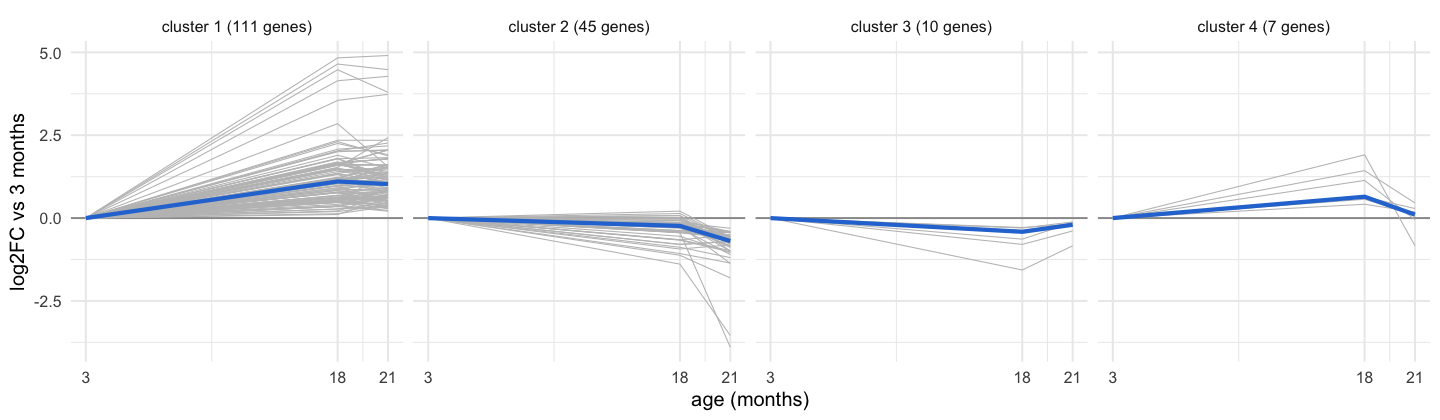

In [10]:
options(repr.plot.width = 12, repr.plot.height = 3.5)
deg_pattern_plot(pat)

**Reading.** Most aging DEGs rise by 18 months and stay up (cluster 1, 111 genes, e.g. the microglia / inflammation genes Cst7, Ccl3, Clec7a, C4b). Most falling genes drop mainly between 18 and 21 months (cluster 2, 45 genes). Clusters 3 and 4 (10 and 7 genes) change at 18 months and partly return at 21; with 3–4 mice per group such transient patterns may be noise. The number of clusters (4) is a choice; with three time points few distinct shapes exist.

## 3 · Rejuvenation: aDR vs AL (females) and YMP vs PBS (males)

In [11]:
# one DESeq2 model per treatment (each against its own control); counts of up / down DEGs
s_adr <- samples %>% filter(group %in% c('AL', 'aDR')) %>% mutate(group = droplevels(group))
s_ymp <- samples %>% filter(group %in% c('PBS', 'YMP')) %>% mutate(group = droplevels(group))
dds_adr <- make_dds(txi, s_adr, ~ group, min_n = 4)
dds_ymp <- make_dds(txi, s_ymp, ~ group, min_n = 3)
rej <- list(aDR = de_table(dds_adr, c('group', 'aDR', 'AL'), genes),
            YMP = de_table(dds_ymp, c('group', 'YMP', 'PBS'), genes))
bind_rows(lapply(rej, n_deg), .id = 'contrast')

contrast,up,down
<chr>,<int>,<int>
aDR,46,72
YMP,22,28


## 4 · Save
One CSV per comparison with all tested genes (DESeq2 columns and gene symbol), read by notebook 05.

In [12]:
# writes results/de/<METHOD>/<comparison>.csv and the aging DEG patterns
res <- c(setNames(age, paste0('aging_', names(age))), rej)
invisible(imap(res, \(r, n) write_csv(r, file.path(ROOT, 'results/de', METHOD, paste0(n, '.csv')))))
write_csv(pat, file.path(ROOT, 'results/de', METHOD, 'aging_deg_patterns.csv'))
list.files(file.path(ROOT, 'results/de', METHOD))

[1] "aDR.csv"                "aging_18v3.csv"         "aging_21v3.csv"        
[4] "aging_deg_patterns.csv" "YMP.csv"